# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | 25 de octubre de 2026 |
| **Estudiante** | @fampueroc |
| **Entorno** | `uv sync --group docai` y `uv sync --group audio` (repositorio del curso, Python 3.12, solo CPU: Intel Core Ultra 7 155H, 32 GB RAM) |
| **OCR** | PaddleOCR 3.7 (PP-OCRv6, motor PaddlePaddle en CPU) — versión exacta impresa abajo |
| **ASR** | faster-whisper 1.2.1 con `large-v3-turbo` (int8, CPU) + VAD Silero; Meta MMS-1b-all `qwh` para los dos clips en quechua de Huaylas |
| **Diarización** | huellas de voz WeSpeaker ResNet34 (pyannote) + clustering jerárquico (`voz.diarizar`, Sesión 13) |
| **Costo** | 0: todos los modelos son abiertos y corren en local; ninguna API de pago |

### Fuentes y licencias

| Corpus | Fuente | Licencia |
|---|---|---|
| 25 documentos (8 impresos, 8 fotos, 9 manuscritos) | Wikimedia Commons — imágenes de archivos peruanos (BNP, Biblioteca Real de Dinamarca para Guamán Poma, fotógrafos de Commons) | Dominio público, CC0, CC BY 3.0/4.0, CC BY-SA 3.0/4.0 |
| 19 entrevistas | Wikimedia Commons (Wikimedia Perú, estudiantes UNMSM, proyecto *Voces y plantas*, *Semillas de Conocimiento*) | CC BY-SA 4.0 / CC BY 4.0 |
| 10 frases leídas | OpenSLR 73, *Crowdsourced high-quality Peruvian Spanish speech* (Google) | CC BY-SA 4.0 |

La licencia y el autor de **cada** archivo se leen de la API de Commons al descargar (no se escriben a mano) y quedan en `datos/fuentes.csv`. El código de descarga y recuperación está en `corpus.py`.
Los archivos originales y las salidas pesadas viven en `datos/raw/` (excluido de Git por `.gitignore`).

In [1]:
import hashlib
import json
import os
import re
import sys
import time
import warnings
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

RAIZ = Path.cwd()                                   # el notebook se ejecuta desde tarea_2/
SESION13 = RAIZ.parent / "sessions" / "13-audio-a-texto"
sys.path.insert(0, str(SESION13))                   # voz.py de la Sesión 13
sys.path.insert(0, str(RAIZ))                       # corpus.py de esta tarea

import corpus
import voz
from voz import SR, Segmento, cargar_audio

DATOS, RAW = RAIZ / "datos", RAIZ / "datos" / "raw"
pio.renderers.default = "notebook_connected+png"    # interactivo en Jupyter y PNG visible en GitHub
pd.set_option("display.max_colwidth", 90)

import importlib.metadata as md
for p in ["paddleocr", "paddlepaddle", "faster-whisper", "transformers", "torch", "pyannote-audio", "jiwer", "plotly"]:
    print(f"{p:15} {md.version(p)}")
print("Dispositivo:", voz.dispositivo())

paddleocr       3.7.0
paddlepaddle    3.3.1
faster-whisper  1.2.1
transformers    5.16.1
torch           2.13.0
pyannote-audio  4.0.7
jiwer           4.0.0
plotly          7.0.0


Dispositivo: cpu


## 1 · Corpus: descarga con licencia registrada

`corpus.py` tiene el catálogo (25 documentos y 29 audios) y descarga cada archivo a `datos/raw/` con un `User-Agent` descriptivo,
1,5 s de pausa entre solicitudes y reintentos cuando el servidor responde *429 Too Many Requests*.
Si el archivo ya está en disco, no se vuelve a pedir.

**Revisión visual previa (humana):** al mirar las 25 imágenes se reclasificaron dos documentos: una postal casi sin texto se
reemplazó, y una carta a Ricardo Palma resultó **mecanografiada** (pasó a *impreso*); en su lugar entró otra página manuscrita de
Guamán Poma. Así se respetan los tres tipos exigidos sin rellenar con texto sintético.

In [2]:
docs = corpus.bajar_documentos()
audios = pd.concat([corpus.bajar_audios_commons(), corpus.bajar_openslr73()], ignore_index=True)

print("Documentos por tipo:", docs["tipo"].value_counts().to_dict())
print(f"Audios: {len(audios)} clips ·", audios["tipo"].value_counts().to_dict())
docs[["id", "tipo", "descripcion", "licencia", "autor"]]

Documentos por tipo: {'manuscrito': 9, 'impreso': 8, 'foto': 8}
Audios: 29 clips · {'entrevista': 19, 'lectura': 10}


,id,tipo,descripcion,licencia,autor
0,doc_001,impreso,"Resolución de alcaldía de Mache, La Libertad (2016)",CC BY 4.0,Helder Zavaleta Verde
1,doc_002,impreso,Billete de 500 000 intis (1988),CC0,ByRussia45
2,doc_003,impreso,Billete de 1000 intis (1988),CC0,ByRussia45
3,doc_004,impreso,Mercurio Peruano (1791),Public domain,El Mercurio Peruano
4,doc_005,impreso,Portada de El Comercio (1945),Public domain,El Comercio (some photos by AP)
5,doc_006,impreso,"El Comercio, número 12 (1839)",CC BY-SA 4.0,El Comercio
6,doc_007,impreso,Portada de la Constitución peruana de 1823,Public domain,Peru
7,doc_008,impreso,Carta mecanografiada a Ricardo Palma (1914),CC0,"Bachmann, Carlos J., 1869-"
8,doc_009,foto,"Placa de la Calle Capón, Lima",CC BY 3.0,Miguel Angel Chong
9,doc_010,foto,"Pizarra de menú escrita con tiza, Lince",CC BY-SA 3.0,Dtarazona


In [3]:
audios[["id", "tipo", "idioma", "descripcion", "licencia"]]

,id,tipo,idioma,descripcion,licencia
0,clip_001,entrevista,es,"Entrevista en la calle a una vendedora, El Agustino (2022)",CC BY-SA 4.0
1,clip_002,entrevista,es,"Entrevista en la calle a dos vendedoras, El Agustino (2022)",CC BY-SA 4.0
2,clip_003,entrevista,es,Dirigente de Fenmucarinap en conferencia de prensa (2022),CC BY-SA 4.0
3,clip_004,entrevista,es,Representante de Fenmucarinap Apurímac en conferencia de prensa,CC BY-SA 4.0
4,clip_005,entrevista,es,"Entrevista con megáfono y música de fondo, Huancayo",CC BY-SA 4.0
5,clip_006,entrevista,es,Mini entrevistas en el medio tiempo del repechaje Perú-Australia,CC BY-SA 4.0
6,clip_007,entrevista,es,Entrevista a una joven en una marcha,CC BY-SA 4.0
7,clip_008,entrevista,es,"Celebración de la Santísima Trinidad, Shuyo (Áncash)",CC BY-SA 4.0
8,clip_009,entrevista,es,"Celebración de la Santísima Trinidad, Pomabamba (Áncash)",CC BY-SA 4.0
9,clip_010,entrevista,es,"Entrevista en una marcha, estudiante UNMSM",CC BY-SA 4.0


## 2 · OCR con PaddleOCR (Sesión 10)

Parámetros (fijados antes de mirar resultados):

- Modelo por defecto de PaddleOCR 3.7: **PP-OCRv6** (detector + reconocedor multilingüe que cubre el español con tildes y eñes).
- `use_doc_orientation_classify=False`, `use_doc_unwarping=False`, `use_textline_orientation=False`, como en la clase: es la
  **configuración base, sin preprocesamiento** de imagen.
- `enable_mkldnn=False`: con PaddlePaddle 3.3 en esta CPU Intel bajo Windows, la aceleración oneDNN falla con
  `NotImplementedError: ConvertPirAttribute2RuntimeAttribute not support`. Desactivarla no cambia el modelo ni el texto, solo la
  velocidad (≈ 1 min por página en CPU). El motor PyTorch (`engine="transformers"`) también se probó, pero fue aún más lento aquí.
- Texto final = líneas en orden de lectura del detector, unidas con espacios. Se descartan líneas con confianza < 0.5
  (en la clase vimos que esas cajas suelen ser trozos del dibujo, no letras).

Respaldo crudo por documento en `datos/raw/documentos/ocr/`: el JSON completo de PaddleOCR (texto, confianza y caja de cada
línea), la imagen con las cajas dibujadas y los **recortes** de cada línea detectada.

In [4]:
from paddleocr import PaddleOCR
from PIL import Image

OPCIONES = dict(use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False,
                enable_mkldnn=False, cpu_threads=16)
CONF_MIN = 0.5
DIR_OCR = RAW / "documentos" / "ocr"
DIR_OCR.mkdir(parents=True, exist_ok=True)
ocr = None


def leer_documento(id_, ruta):
    "OCR de una imagen con respaldo en disco: si ya existe el JSON, no se vuelve a correr el modelo."
    global ocr
    crudo = DIR_OCR / f"{id_}.json"
    if not crudo.exists():
        if ocr is None:
            ocr = PaddleOCR(**OPCIONES)
        t0 = time.perf_counter()
        r = ocr.predict(str(ruta))[0]
        segundos = time.perf_counter() - t0
        r.save_to_img(str(DIR_OCR / f"{id_}_cajas.jpg"))
        cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4).tolist()
        datos = {"rec_texts": list(r["rec_texts"]), "rec_scores": [float(s) for s in r["rec_scores"]],
                 "rec_boxes": cajas, "segundos": segundos}
        crudo.write_text(json.dumps(datos, ensure_ascii=False), encoding="utf-8")
        # recortes de cada línea detectada
        img = Image.open(ruta).convert("RGB")
        dir_rec = DIR_OCR / f"{id_}_recortes"
        dir_rec.mkdir(exist_ok=True)
        for k, (x0, y0, x1, y1) in enumerate(cajas):
            img.crop((x0, y0, x1, y1)).save(dir_rec / f"linea_{k:03d}.jpg", quality=85)
    return json.loads(crudo.read_text(encoding="utf-8"))


filas = []
for d in docs.itertuples():
    r = leer_documento(d.id, RAIZ / d.archivo)
    lineas = [(t, s) for t, s in zip(r["rec_texts"], r["rec_scores"]) if s >= CONF_MIN and t.strip()]
    filas.append({"id": d.id, "n_lineas": len(r["rec_texts"]), "n_lineas_ok": len(lineas),
                  "conf_mediana": np.median(r["rec_scores"]) if r["rec_scores"] else np.nan,
                  "segundos": r["segundos"], "texto_ocr_crudo": " ".join(t for t, _ in lineas)})
ocr_res = docs[["id", "tipo"]].merge(pd.DataFrame(filas), on="id")
print(f"OCR de {len(ocr_res)} documentos · {ocr_res['segundos'].sum():.0f} s de cómputo en CPU "
      f"({ocr_res['segundos'].mean():.1f} s por página)")
ocr_res.groupby("tipo")[["n_lineas_ok", "conf_mediana", "segundos"]].median().round(2)

OCR de 25 documentos · 2153 s de cómputo en CPU (86.1 s por página)


,n_lineas_ok,conf_mediana,segundos
tipo,,,
foto,7.5,0.97,69.91
impreso,27.0,0.99,74.80
manuscrito,16.0,0.74,45.73


In [5]:
ocr_res[["id", "tipo", "n_lineas", "n_lineas_ok", "conf_mediana", "texto_ocr_crudo"]].round(3)

,id,tipo,n_lineas,n_lineas_ok,conf_mediana,texto_ocr_crudo
0,doc_001,impreso,28,28,0.993,SE RESUELVE: .- Artículo 1°- RECONOCER como lema ganador en el Concurso Público Creaci...
1,doc_002,impreso,14,14,0.999,BANCOCENTRALDERESERVADELPERU 500000 A4962929H Y QUINIENTOS MILINTIS RICARDOPALMA D 85 ...
2,doc_003,impreso,10,10,0.996,BANCO CENTRAL DERESERVADELPERU B6075029N MILINTS Whifaje 85 DIRECTOR 28 DE JUNIO DE 19...
3,doc_004,impreso,44,43,0.969,Eol. 25 MERCURIO PERUANO DEL DIA 13. DE ENERO DE 1791. EXAMEN HISTÓRICO DE LAS DIVERSI...
4,doc_005,impreso,304,303,0.980,El Comercio JABON IMPERIAL ara la tersura de sx cutis.. sin igual LECHEdeALMENDRAS and...
5,doc_006,impreso,230,230,0.990,Bste periódieo se despacha en esta Capital Los avisos que deban sanr en este en a tien...
6,doc_007,impreso,6,6,0.874,ONSTITUCION POLITICA LA TLHUBMICA IFFUANA Lima 1823
7,doc_008,impreso,26,26,0.975,"6x Maldonado, 4 de julio de 1914. Señor Don Ricardo Palma, Lime. Muy distinguido señor..."
8,doc_009,foto,9,8,0.999,Baby Boy BARRIO CHINO GAS HELIO CALLE 10 CAPON BACKYARDI
9,doc_010,foto,22,22,0.950,ENTRADAS SEGUNDOS Postres Gnocchi TacuTacu+ *Strudelde Cevicheclepsdo Lomosaltado manz...


La confianza mediana cae de impresos a fotos y a manuscritos, como en la escalera de dificultad de la Sesión 10.
Recordatorio de la clase: **una confianza alta no garantiza un dato correcto**; por eso en la Parte 2 se mide el CER contra
referencias manuales.

## 3 · ASR con faster-whisper + VAD + diarización (Sesión 13)

- **faster-whisper `large-v3-turbo`** (`int8` en CPU), `beam_size=5`, `language="es"` y **`vad_filter=True`** (Silero VAD): el VAD
  impide que Whisper "oiga" frases en los silencios o en la música (alucinaciones vistas en clase).
- **Quechua de Huaylas** (`clip_018`, `clip_019`): Whisper no tiene quechua y lo convierte en castellano inventado, así que para
  esos dos clips se usa **Meta MMS-1b-all con el adaptador `qwh`**, sobre los tramos de voz que marca el VAD.
- **Diarización** en todas las entrevistas: huella de voz por segmento y clustering con umbral 0.7 (`voz.diarizar`). Las frases
  leídas de OpenSLR son de un solo hablante por diseño.
- Exportación por clip a `datos/raw/audio/salidas/`: **CSV** de segmentos, **SRT** y **TXT**.

In [6]:
from faster_whisper import WhisperModel

DIR_ASR = RAW / "audio" / "salidas"
DIR_ASR.mkdir(parents=True, exist_ok=True)
MODELO_WHISPER = "mobiuslabsgmbh/faster-whisper-large-v3-turbo"
_modelos = {}


def whisper():
    if "whisper" not in _modelos:
        _modelos["whisper"] = WhisperModel(MODELO_WHISPER, device="cpu", compute_type="int8", cpu_threads=16)
    return _modelos["whisper"]


def mms_qwh():
    if "mms" not in _modelos:
        _modelos["mms"] = voz.Transcriptor("mms", device="cpu", idioma_mms="qwh")
    return _modelos["mms"]


def transcribir_clip(a):
    "Transcribe, diariza y exporta un clip. Usa la caché en disco si ya se procesó."
    cache = DIR_ASR / f"{a.id}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    x = cargar_audio(RAIZ / a.archivo)
    dur = len(x) / SR
    voz_tramos = voz.tramos_de_voz(x)
    seg_voz = sum(b - a_ for a_, b in voz_tramos)
    t0 = time.perf_counter()
    if a.idioma == "qwh":
        modelo = "Meta MMS-1b-all [qwh] (VAD Silero)"
        segs = mms_qwh().segmentos(x)
    else:
        modelo = "faster-whisper large-v3-turbo int8 (VAD on, beam 5)"
        res, _ = whisper().transcribe(x, language="es", beam_size=5, vad_filter=True,
                                      vad_parameters={"min_silence_duration_ms": 300})
        segs = [Segmento(round(s.start, 2), round(s.end, 2), s.text.strip()) for s in res if s.text.strip()]
    t_asr = time.perf_counter() - t0
    if a.tipo == "entrevista" and len(segs) > 1:
        segs = voz.diarizar(x, segs, umbral=0.7, device="cpu")
    else:
        segs = [Segmento(s.inicio, s.fin, s.texto, "H1") for s in segs]
    voz.a_tabla(segs).to_csv(DIR_ASR / f"{a.id}.csv", index=False)
    (DIR_ASR / f"{a.id}.srt").write_text(voz.a_srt(segs), encoding="utf-8")
    (DIR_ASR / f"{a.id}.txt").write_text(voz.a_texto(segs), encoding="utf-8")
    salida = {"duracion_seg": dur, "segundos_voz": seg_voz, "segundos_asr": t_asr, "modelo_asr": modelo,
              "segmentos": [vars(s) for s in segs]}
    cache.write_text(json.dumps(salida, ensure_ascii=False), encoding="utf-8")
    return salida


def con_marcas(segmentos):
    "Une segmentos seguidos del mismo hablante: '[HABLANTE_1] ... [HABLANTE_2] ...'."
    turnos = []
    for s in segmentos:
        h = "HABLANTE_" + s["hablante"].lstrip("H")
        if turnos and turnos[-1][0] == h:
            turnos[-1][1].append(s["texto"])
        else:
            turnos.append([h, [s["texto"]]])
    return " ".join(f"[{h}] {' '.join(t)}" for h, t in turnos)


t0 = time.perf_counter()
filas = []
for a in audios.itertuples():
    r = transcribir_clip(a)
    filas.append({"id": a.id, "duracion_seg": round(r["duracion_seg"], 1), "segundos_voz": round(r["segundos_voz"], 1),
                  "idioma": a.idioma, "modelo_asr": r["modelo_asr"],
                  "n_hablantes": len({s["hablante"] for s in r["segmentos"]}),
                  "rtf": r["segundos_asr"] / r["duracion_seg"], "texto_asr_crudo": con_marcas(r["segmentos"])})
asr_res = audios[["id", "tipo", "archivo"]].merge(pd.DataFrame(filas), on="id")
print(f"{len(asr_res)} clips · {asr_res['duracion_seg'].sum() / 60:.1f} min de audio · "
      f"factor de tiempo real medio {asr_res['rtf'].mean():.2f} (en esta sesión: {time.perf_counter() - t0:.0f} s)")
asr_res[["id", "tipo", "idioma", "duracion_seg", "segundos_voz", "n_hablantes", "rtf"]].round(2)

29 clips · 44.7 min de audio · factor de tiempo real medio 1.15 (en esta sesión: 0 s)


,id,tipo,idioma,duracion_seg,segundos_voz,n_hablantes,rtf
0,clip_001,entrevista,es,136.3,105.5,3,0.66
1,clip_002,entrevista,es,189.0,156.6,3,0.67
2,clip_003,entrevista,es,250.6,239.0,1,0.49
3,clip_004,entrevista,es,497.7,478.7,2,0.70
4,clip_005,entrevista,es,261.6,249.5,2,0.67
5,clip_006,entrevista,es,29.9,27.1,2,0.92
6,clip_007,entrevista,es,54.3,52.8,2,0.52
7,clip_008,entrevista,es,98.3,10.5,1,0.16
8,clip_009,entrevista,es,81.6,78.3,3,0.97
9,clip_010,entrevista,es,77.4,70.4,2,0.57


## 4 · Seudonimización

Criterio (revisión humana de **todos** los textos OCR y ASR antes de publicarlos):

- **Se reemplazan** nombres de personas privadas (entrevistadas, vecinos, entrevistadores, autoridades locales vivas y familiares
  en registros civiles), DNI y teléfonos. Se usa `voz.seudonimizar`, que compara con *rapidfuzz* y atrapa nombres mal escritos
  por el modelo (p. ej. "Vásquez" / "Vázquez").
- **Se mantienen** personajes históricos y figuras públicas que son el tema del documento (Ricardo Palma, Guamán Poma, San
  Martín, autoridades de 1821, etc.): no son datos personales privados.
- Además, expresiones regulares para números de 8 dígitos (DNI) y de 9 dígitos que empiezan con 9 (celulares).

El diccionario de reemplazos se construyó leyendo las salidas crudas de las secciones 2 y 3. **No se publica**: contiene
justamente los nombres reales, así que vive en `datos/raw/seudonimos.json` (fuera de Git) y aquí solo se reporta cuántos
reemplazos hubo.

In [7]:
# {"documentos": {nombre real: seudónimo}, "audio": {...}} — archivo privado, excluido de Git
_s = json.loads((RAW / "seudonimos.json").read_text(encoding="utf-8")) if (RAW / "seudonimos.json").exists() else {}
REEMPLAZOS_DOCS, REEMPLAZOS_AUDIO = _s.get("documentos", {}), _s.get("audio", {})
print(f"Diccionario privado: {len(REEMPLAZOS_DOCS)} nombres en documentos y {len(REEMPLAZOS_AUDIO)} en audio")
PATRONES = {r"\b\d{8}\b": "[DNI]", r"\b9\d{8}\b": "[TELEFONO]"}


def seudonimizar(texto, reemplazos):
    nuevo = voz.seudonimizar(texto, reemplazos, parecido=85)
    for patron, etiqueta in PATRONES.items():
        nuevo = re.sub(patron, etiqueta, nuevo)
    return nuevo


def contar(antes, despues):
    "Entidades reemplazadas = etiquetas nuevas que aparecen tras seudonimizar."
    patron = r"\[(PERSONA|AUTORIDAD|ENTREVISTADOR|DNI|TELEFONO)[^\]]*\]"
    return len(re.findall(patron, despues)) - len(re.findall(patron, antes))


ocr_res["texto_ocr"] = [seudonimizar(t, REEMPLAZOS_DOCS) for t in ocr_res["texto_ocr_crudo"]]
asr_res["texto_asr"] = [seudonimizar(t, REEMPLAZOS_AUDIO) for t in asr_res["texto_asr_crudo"]]
ocr_res["entidades"] = [contar(a, b) for a, b in zip(ocr_res["texto_ocr_crudo"], ocr_res["texto_ocr"])]
asr_res["entidades"] = [contar(a, b) for a, b in zip(asr_res["texto_asr_crudo"], asr_res["texto_asr"])]
print(f"Entidades reemplazadas: {ocr_res['entidades'].sum()} en documentos y {asr_res['entidades'].sum()} en audio")
pd.concat([ocr_res.loc[ocr_res["entidades"] > 0, ["id", "entidades"]],
           asr_res.loc[asr_res["entidades"] > 0, ["id", "entidades"]]])

Diccionario privado: 5 nombres en documentos y 37 en audio


Entidades reemplazadas: 6 en documentos y 35 en audio


,id,entidades
0,doc_001,6
0,clip_001,2
1,clip_002,10
2,clip_003,1
3,clip_004,2
4,clip_005,3
6,clip_007,1
8,clip_009,1
9,clip_010,2
10,clip_011,2


In [8]:
# Diarización ya seudonimizada: entrevista en la calle con dos vendedoras (El Agustino)
a = next(r for r in audios.itertuples() if r.id == "clip_002")
for s in transcribir_clip(a)["segmentos"][:14]:
    print(f"[{s['inicio']:6.1f} s] {s['hablante']}: {seudonimizar(s['texto'], REEMPLAZOS_AUDIO)}")

[   0.0 s] H1: Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entrevista acerca del fútbol como unión de masas.
[   8.7 s] H1: Estoy con las señoras...
[  10.6 s] H2: [PERSONA_6], soy [PERSONA_7].
[  13.4 s] H1: Muy bien, voy a comenzar con la primera pregunta y es, ¿qué expectativas tienen ante este partido?
[  22.0 s] H3: Que el afición se encuentra motivado para ganar este partido.
[  30.4 s] H1: ¿Me puede decir su nombre?
[  32.2 s] H3: [PERSONA_6].
[  34.0 s] H2: La expectativa que yo pienso es que acá, que el Perú va a dar todo por todo, todo su corazón va a entregar para que ganemos, para que ganemos para ir a las olimpiadas.
[  48.5 s] H1: Al mundial.
[  49.1 s] H2: Al mundial.
[  49.9 s] H1: ¿Me puede decir este su nombre?
[  51.4 s] H2: [PERSONA_7].
[  52.8 s] H1: Bien, sigo con la siguiente pregunta.
[  56.5 s] H1: ¿Qué jugador piensa que va a ser el más determinante?


## 5 · Limpieza: duplicados por hash y descartes

- **Duplicados:** SHA-256 de los **bytes del archivo** (no del texto), así dos descargas del mismo archivo con distinto nombre se
  detectan aunque el OCR difiera.
- **Descartes:** un documento es *ilegible* cuando **una persona** no puede leerlo (revisión visual de las 25 imágenes: ninguno lo
  fue; los dos casos dudosos se reemplazaron antes, ver sección 1). Que el **OCR** no lea nada no es motivo de descarte: es un
  fallo del modelo y se conserva como caso difícil para la Parte 2. Audio *sin voz*: el VAD encuentra menos de 10 % de voz o la
  transcripción queda vacía. Lo descartado se reporta y, según las reglas, se reemplaza.

In [9]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()


docs["sha256"] = [sha256(RAIZ / r) for r in docs["archivo"]]
audios["sha256"] = [sha256(RAIZ / r) for r in audios["archivo"]]
dup_docs = docs[docs["sha256"].duplicated()]
dup_audio = audios[audios["sha256"].duplicated()]
print(f"Duplicados por hash: {len(dup_docs)} documentos, {len(dup_audio)} audios")

ILEGIBLES_REVISION_HUMANA = []          # resultado de mirar las 25 imágenes
ilegibles = ocr_res[ocr_res["id"].isin(ILEGIBLES_REVISION_HUMANA)]
fallo_ocr = ocr_res[ocr_res["n_lineas_ok"] == 0]
sin_voz = asr_res[(asr_res["segundos_voz"] / asr_res["duracion_seg"] < 0.10) | (asr_res["texto_asr"].str.len() == 0)]
print(f"Documentos ilegibles (revisión humana): {len(ilegibles)} {ilegibles['id'].tolist()}")
print(f"Documentos legibles donde el OCR no leyó nada (se conservan como caso difícil): {fallo_ocr['id'].tolist()}")
print(f"Audios sin voz: {len(sin_voz)} {sin_voz['id'].tolist()}")

descartar = set(dup_docs["id"]) | set(ilegibles["id"]) | set(dup_audio["id"]) | set(sin_voz["id"])
ocr_res = ocr_res[~ocr_res["id"].isin(descartar)].reset_index(drop=True)
asr_res = asr_res[~asr_res["id"].isin(descartar)].reset_index(drop=True)
print(f"Quedan {len(ocr_res)} documentos ({ocr_res['tipo'].value_counts().to_dict()}) y {len(asr_res)} clips "
      f"({asr_res['duracion_seg'].sum() / 60:.1f} min)")
assert len(ocr_res) >= 25 and asr_res["duracion_seg"].sum() >= 30 * 60 and len(asr_res) >= 20
assert (asr_res["n_hablantes"] >= 2).any(), "se necesita al menos un audio multihablante"

Duplicados por hash: 0 documentos, 0 audios


Documentos ilegibles (revisión humana): 0 []
Documentos legibles donde el OCR no leyó nada (se conservan como caso difícil): ['doc_011']
Audios sin voz: 0 []
Quedan 25 documentos ({'manuscrito': 9, 'impreso': 8, 'foto': 8}) y 29 clips (44.7 min)


## 6 · Análisis exploratorio (Plotly Express)

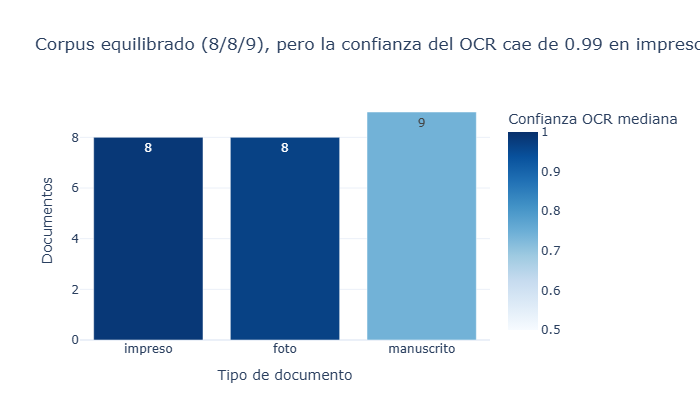

In [10]:
ocr_res["caracteres"] = ocr_res["texto_ocr"].str.len()
asr_res["palabras"] = asr_res["texto_asr"].str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()
conf = ocr_res.groupby("tipo")["conf_mediana"].median()
orden_tipos = ["impreso", "foto", "manuscrito"]

g1 = (ocr_res.groupby("tipo").agg(documentos=("id", "size"), confianza=("conf_mediana", "median"))
      .reindex(orden_tipos).reset_index())
fig1 = px.bar(g1, x="tipo", y="documentos", text="documentos", color="confianza", range_color=(0.5, 1),
              color_continuous_scale="Blues", labels={"tipo": "Tipo de documento", "documentos": "Documentos",
                                                       "confianza": "Confianza OCR mediana"},
              title=(f"Corpus equilibrado (8/8/9), pero la confianza del OCR cae de {conf['impreso']:.2f} en impresos "
                     f"a {conf['manuscrito']:.2f} en manuscritos"))
fig1.update_layout(template="plotly_white", height=420)
fig1.show()

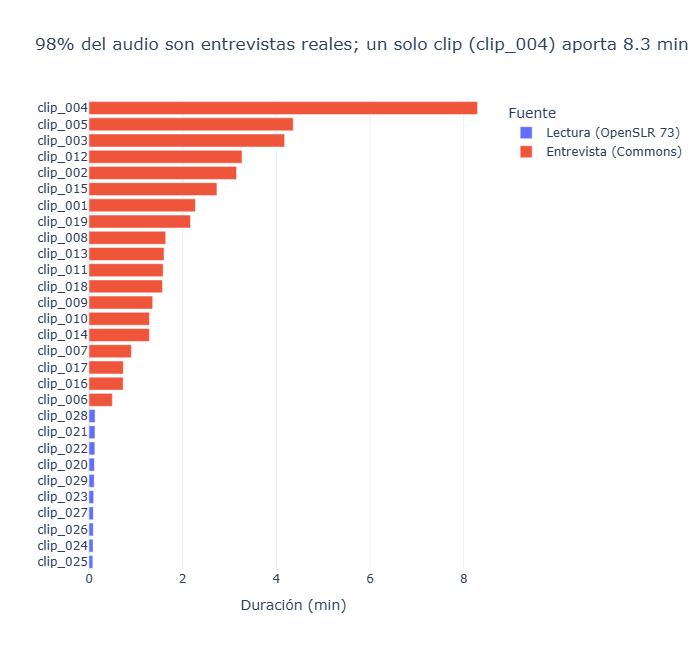

In [11]:
fuente = {"entrevista": "Entrevista (Commons)", "lectura": "Lectura (OpenSLR 73)"}
g2 = asr_res.assign(fuente=asr_res["tipo"].map(fuente), minutos=asr_res["duracion_seg"] / 60).sort_values("duracion_seg")
largo = g2.iloc[-1]
fig2 = px.bar(g2, x="minutos", y="id", color="fuente", orientation="h",
              labels={"minutos": "Duración (min)", "id": "", "fuente": "Fuente"},
              title=(f"{g2.loc[g2['tipo'] == 'entrevista', 'minutos'].sum() / g2['minutos'].sum():.0%} del audio son "
                     f"entrevistas reales; un solo clip ({largo['id']}) aporta {largo['minutos']:.1f} min"))
fig2.update_layout(template="plotly_white", height=650)
fig2.show()

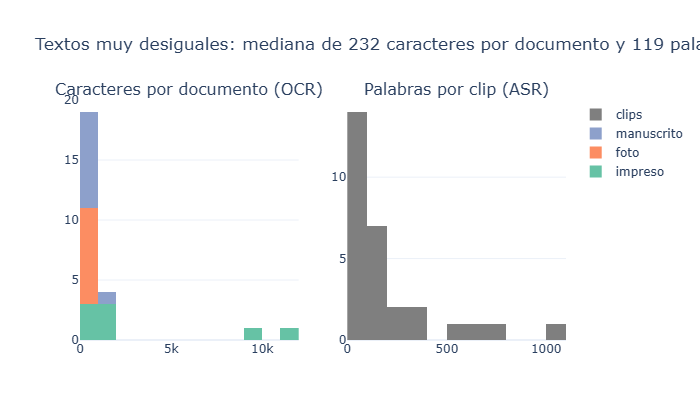

In [12]:
from plotly.subplots import make_subplots

fig3 = make_subplots(rows=1, cols=2, subplot_titles=("Caracteres por documento (OCR)", "Palabras por clip (ASR)"))
for tipo, color in zip(orden_tipos, px.colors.qualitative.Set2):
    fig3.add_histogram(x=ocr_res.loc[ocr_res["tipo"] == tipo, "caracteres"], name=tipo, nbinsx=12,
                       marker_color=color, row=1, col=1)
fig3.add_histogram(x=asr_res["palabras"], name="clips", nbinsx=15, marker_color="#7f7f7f", row=1, col=2)
fig3.update_layout(barmode="stack", template="plotly_white", height=420,
                   title=(f"Textos muy desiguales: mediana de {ocr_res['caracteres'].median():.0f} caracteres por documento "
                          f"y {asr_res['palabras'].median():.0f} palabras por clip, con colas largas de prensa y entrevistas"))
fig3.show()

## 7 · Validación de extremos

In [13]:
def extremos(df, col, texto, n=3):
    o = df.sort_values(col)
    return pd.concat([o.tail(n).assign(extremo="más largo"), o.head(n).assign(extremo="más corto")])[["extremo", "id", col, texto]]


print("Documentos con OCR más largo y más corto:")
display(extremos(ocr_res.assign(inicio=ocr_res["texto_ocr"].str[:90]), "caracteres", "inicio"))
print("Clips más largos y más cortos:")
display(extremos(asr_res.assign(inicio=asr_res["texto_asr"].str[:90]), "duracion_seg", "inicio"))

Documentos con OCR más largo y más corto:


,extremo,id,caracteres,inicio
3,más largo,doc_004,1663,Eol. 25 MERCURIO PERUANO DEL DIA 13. DE ENERO DE 1791. EXAMEN HISTÓRICO DE LAS DIVERSI...
5,más largo,doc_006,9170,Bste periódieo se despacha en esta Capital Los avisos que deban sanr en este en a tien...
4,más largo,doc_005,11933,El Comercio JABON IMPERIAL ara la tersura de sx cutis.. sin igual LECHEdeALMENDRAS and...
10,más corto,doc_011,0,
11,más corto,doc_012,16,ANCO DL HERRADOR
6,más corto,doc_007,51,ONSTITUCION POLITICA LA TLHUBMICA IFFUANA Lima 1823


Clips más largos y más cortos:


,extremo,id,duracion_seg,inicio
2,más largo,clip_003,250.6,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio ento...
4,más largo,clip_005,261.6,"[HABLANTE_1] Hola. Bien, hola. Estamos aquí en la Plaza Mayor de Huancayo y bueno, est..."
3,más largo,clip_004,497.7,"[HABLANTE_1] Bien, estamos en Plaza San Martín. Antes que nada, ¿me podría decir su no..."
24,más corto,clip_025,4.9,[HABLANTE_1] ¿Qué fue lo que hizo el presidente Trump cuando llegó a Puerto Rico?
23,más corto,clip_024,5.2,[HABLANTE_1] Me gustaría saber cuáles son los requisitos para formar parte de este club
25,más corto,clip_026,5.5,[HABLANTE_1] Su gol fue chilena o fue tiro de esquina


Los extremos son coherentes con los histogramas: las portadas de periódico y las cartas largas forman la cola derecha de
caracteres, y los billetes, letreros y placas la izquierda. En audio, la conferencia de prensa más larga y las frases leídas de
OpenSLR (de 4 a 8 s) marcan los dos extremos del gráfico de duración.

## 8 · Exportación

In [14]:
documentos = docs[["id", "archivo", "tipo"]].merge(ocr_res[["id", "texto_ocr"]], on="id")
documentos["fuente"] = docs.set_index("id").loc[documentos["id"]].apply(
    lambda d: f"Wikimedia Commons ({d['licencia']})", axis=1).values
documentos["modelo_ocr"] = f"PaddleOCR {md.version('paddleocr')} (PP-OCRv6, sin preprocesamiento, conf>={CONF_MIN})"
documentos["texto_referencia"] = ""          # se completa en la Parte 2 (muestra de evaluación)
documentos = documentos[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]]

transcripciones = asr_res.rename(columns={"archivo": "archivo_audio"})
transcripciones["texto_referencia"] = ""
transcripciones = transcripciones[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr",
                                   "n_hablantes", "texto_referencia"]]

fuentes = pd.concat([docs, audios], ignore_index=True)
fuentes["fuente_url"] = fuentes["url_pagina"]
fuentes["acceso"] = np.where(
    fuentes["titulo_commons"].notna(),
    "corpus.py: API de Commons (imageinfo) -> " + np.where(fuentes["modalidad"] == "documento",
                                                         "miniatura de 1600 px", "archivo original"),
    "corpus.py: lectura parcial (HTTP Range) del zip de OpenSLR 73, archivo " + fuentes["archivo_slr"].fillna(""))
# URL pública para el dashboard: miniaturas de documentos (salvo doc_001) y solo los audios de Commons cuya transcripción no
# tuvo nombres que seudonimizar y cuyo título de archivo no nombra a la persona (el nombre del archivo va dentro de la URL)
TITULO_CON_NOMBRE = {"clip_003", "clip_004", "clip_008", "clip_009", "clip_010", "clip_011", "clip_016", "clip_017", "clip_018", "clip_019"}
con_entidades = set(asr_res.loc[asr_res["entidades"] > 0, "id"])
publicable = (fuentes["modalidad"] == "documento") & (fuentes["id"] != "doc_001") | \
             (fuentes["modalidad"] == "audio") & ~fuentes["id"].isin(TITULO_CON_NOMBRE | con_entidades)
fuentes["url_publica"] = np.where(publicable, fuentes["url_descarga"].fillna(""), "")
# el autor (quien grabó o subió) se conserva para la atribución, salvo que coincida con una persona seudonimizada
fuentes["autor"] = [("ver página de Commons (fuente_url)" if any(n.lower() in str(a).lower() for n in REEMPLAZOS_AUDIO if len(n) > 5)
                     else a) for a in fuentes["autor"]]
fuentes = fuentes[["id", "modalidad", "tipo", "descripcion", "fuente_url", "licencia", "autor", "acceso", "url_publica", "sha256"]]

# segmentos con tiempo y hablante (seudonimizados) para el visor "quién dijo qué" del dashboard
segmentos = pd.DataFrame([{"id": a.id, **s, "texto": seudonimizar(s["texto"], REEMPLAZOS_AUDIO)}
                          for a in audios[audios["id"].isin(asr_res["id"])].itertuples()
                          for s in transcribir_clip(a)["segmentos"]])
segmentos.to_csv(DATOS / "segmentos.csv", index=False)

documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
fuentes.to_csv(DATOS / "fuentes.csv", index=False)
for nombre, df in [("documentos", documentos), ("transcripciones", transcripciones), ("fuentes", fuentes)]:
    print(f"datos/{nombre}.csv -> {df.shape}")
documentos.head()

datos/documentos.csv -> (25, 7)
datos/transcripciones.csv -> (29, 8)
datos/fuentes.csv -> (54, 10)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (CC BY 4.0),SE RESUELVE: .- Artículo 1°- RECONOCER como lema ganador en el Concurso Público Creaci...,"PaddleOCR 3.7.0 (PP-OCRv6, sin preprocesamiento, conf>=0.5)",
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (CC0),BANCOCENTRALDERESERVADELPERU 500000 A4962929H Y QUINIENTOS MILINTIS RICARDOPALMA D 85 ...,"PaddleOCR 3.7.0 (PP-OCRv6, sin preprocesamiento, conf>=0.5)",
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (CC0),BANCO CENTRAL DERESERVADELPERU B6075029N MILINTS Whifaje 85 DIRECTOR 28 DE JUNIO DE 19...,"PaddleOCR 3.7.0 (PP-OCRv6, sin preprocesamiento, conf>=0.5)",
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (Public domain),Eol. 25 MERCURIO PERUANO DEL DIA 13. DE ENERO DE 1791. EXAMEN HISTÓRICO DE LAS DIVERSI...,"PaddleOCR 3.7.0 (PP-OCRv6, sin preprocesamiento, conf>=0.5)",
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (Public domain),El Comercio JABON IMPERIAL ara la tersura de sx cutis.. sin igual LECHEdeALMENDRAS and...,"PaddleOCR 3.7.0 (PP-OCRv6, sin preprocesamiento, conf>=0.5)",


In [15]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.ogg,136.3,es,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...","faster-whisper large-v3-turbo int8 (VAD on, beam 5)",3,
1,clip_002,datos/raw/audio/clip_002.ogg,189.0,es,"[HABLANTE_1] Buenos días profesores y compañeros, hoy estoy cerca de aquí por mi casa ...","faster-whisper large-v3-turbo int8 (VAD on, beam 5)",3,
2,clip_003,datos/raw/audio/clip_003.mp3,250.6,es,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio ento...,"faster-whisper large-v3-turbo int8 (VAD on, beam 5)",1,
3,clip_004,datos/raw/audio/clip_004.mp3,497.7,es,"[HABLANTE_1] Bien, estamos en Plaza San Martín. Antes que nada, ¿me podría decir su no...","faster-whisper large-v3-turbo int8 (VAD on, beam 5)",2,
4,clip_005,datos/raw/audio/clip_005.mp3,261.6,es,"[HABLANTE_1] Hola. Bien, hola. Estamos aquí en la Plaza Mayor de Huancayo y bueno, est...","faster-whisper large-v3-turbo int8 (VAD on, beam 5)",2,


In [16]:
fuentes.head()

,id,modalidad,tipo,descripcion,fuente_url,licencia,autor,acceso,url_publica,sha256
0,doc_001,documento,impreso,"Resolución de alcaldía de Mache, La Libertad (2016)",https://commons.wikimedia.org/?curid=141457339,CC BY 4.0,Helder Zavaleta Verde,corpus.py: API de Commons (imageinfo) -> miniatura de 1600 px,,adb9d2600dc2cf88724852d648da52a4845a160c59d10670cde102aec90a73f5
1,doc_002,documento,impreso,Billete de 500 000 intis (1988),https://commons.wikimedia.org/?curid=157624783,CC0,ByRussia45,corpus.py: API de Commons (imageinfo) -> miniatura de 1600 px,https://thumb.wikimedia.org/wikipedia/commons/thumb/6/66/500000_Intis_1988%28Front%29....,f307f463632b619bfbb17ca79b2cde6fd5225c9ab8156c63a87bd527c78d53a3
2,doc_003,documento,impreso,Billete de 1000 intis (1988),https://commons.wikimedia.org/?curid=157624599,CC0,ByRussia45,corpus.py: API de Commons (imageinfo) -> miniatura de 1600 px,https://thumb.wikimedia.org/wikipedia/commons/thumb/0/09/1000_Intis_1988%28Front%29.jp...,b119aa9ff14f8e574f67196c4ca08b660a6bdfaa5c1958e3266b065c9c312b61
3,doc_004,documento,impreso,Mercurio Peruano (1791),https://commons.wikimedia.org/?curid=25748028,Public domain,El Mercurio Peruano,corpus.py: API de Commons (imageinfo) -> miniatura de 1600 px,https://upload.wikimedia.org/wikipedia/commons/a/ab/Pisco-punch-mercurio-peruano-1791.jpg,96521e87507cba15848704f2770055c189c1a9ca7f5d848d44496f8fc2a16f81
4,doc_005,documento,impreso,Portada de El Comercio (1945),https://commons.wikimedia.org/?curid=108362710,Public domain,El Comercio (some photos by AP),corpus.py: API de Commons (imageinfo) -> miniatura de 1600 px,https://upload.wikimedia.org/wikipedia/commons/c/c9/El_Comercio_1945.jpg,6e92472ba6d497327c5dc5dbe12816052769439d3c32ce725e4d12dca9607b30
